# Coat Policy Tuning Report — re-ranking protocol

Audits the tuning artifacts written by `runners/in_distribution/policy_tuning_rerank/run.py`, which
produces the `coat` roster in `configs/policies/preference.json`.

**This is not the ml-1m report.** `notebooks/policy_tuning_ml-m1_interaction.ipynb` audits a
different protocol, and most of its panels have nothing to read here:

| | ml-1m / steam | coat |
| --- | --- | --- |
| split seeds | 10 | 1 — no cross-seed stability, shared-config selection, or seed-noise panel |
| sampler | `TPESampler`, resamples configs | `GridSampler`, `n_trials == grid_size` — coverage is 100% and there are no duplicate trials to measure determinism from |
| candidates | free retrieval over the catalog | re-rank the user's own 16-item held-out pool |
| validation rows | inner 25% split of outer train | the held-out MCAR half — **also the evaluation set** |
| objective | `macro_by_user_group_mean.ndcg@10` | `mean_hit_rate`, the runner's own utility |

Coat forces this. Its train half holds 22.74 rows per user, so a 25% inner split leaves 5.68
candidates against `POLICY_K = 5` — a top-5 covering 88% of the pool, where no setting can
distinguish itself. Scoring free retrieval instead is worse: with 5.68 labelled cells among 300
items, the zero-fill would fabricate ~98% of the objective.

So the only usable validation labels Coat has are the ones the experiment reports against, and
**the panels below are mostly about what that costs**. §5 is the centre of the notebook.

Two artifacts are read together: the *production* roster, tuned on all 290 evaluation users, and the
*diagnostic*, tuned on a seeded 145 and scored on both halves. Only the diagnostic can measure the
selection bias.

## 1. Setup

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 200)


def find_repo_root(start: Path | None = None) -> Path:
    path = (start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "pyproject.toml").exists() and candidate.name == "beyond-click-sim":
            return candidate
    raise RuntimeError("Could not find beyond-click-sim repo root")


REPO_ROOT = find_repo_root()
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from beyond_click_sim.analysis import policy_tuning_rerank_report as report

DATASET = "coat"
TARGET = "target_like_ge4"
SEED = 0
ARTIFACTS_DIR = REPO_ROOT / "artifacts"
RUNS_DIR = REPO_ROOT / "outputs" / "in_distribution" / "policy_ranking_agreement_rerank"

SAVE_FIGS = False
FIG_DIR = REPO_ROOT / "outputs" / "figures" / "policy_tuning_rerank_coat"

report.apply_style()

/Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load

`arts` holds four flat tables — `identity`, `selection`, `trials`, `curse` — plus the raw payloads.
`trials` is the complete log: one row per (arm, policy, grid point), carrying the objective, the
ranking block, wall time, and every hyperparameter under a `param__` prefix. Nothing is aggregated,
so any panel below can be rebuilt from it.

In [2]:
arts = report.load_rerank_artifacts(
    DATASET,
    ARTIFACTS_DIR,
    target=TARGET,
    seed=SEED,
)
arts

RerankTuningArtifacts(policies=6, trials=1418, diagnostic=yes)

In [3]:
# Everything recorded for one policy, unused columns dropped.
arts.grid(arts.tuned_policies[0]).head()

,arm,policy,number,objective,is_selected,tuning_utility,holdout_utility,fallback_users,seconds,ndcg@5,hit_rate@5,param__alpha,param__iterations,param__n_factors,param__regularization,gap
0,production,ALSPolicy,0,0.242759,False,0.242759,NaN,3,0.211686,0.504853,0.675862,5.0,100.0,8.0,1.0000,NaN
1,production,ALSPolicy,1,0.226207,False,0.226207,NaN,3,0.069889,0.473471,0.641379,20.0,50.0,16.0,0.0001,NaN
2,production,ALSPolicy,2,0.256552,False,0.256552,NaN,3,0.071551,0.491967,0.662069,20.0,100.0,1.0,0.1000,NaN
3,production,ALSPolicy,3,0.237241,False,0.237241,NaN,3,0.051938,0.487096,0.644828,5.0,10.0,16.0,1.0000,NaN
4,production,ALSPolicy,4,0.261379,False,0.261379,NaN,3,0.071665,0.504861,0.689655,100.0,100.0,1.0,0.1000,NaN


## 3. Provenance and invariants

The gate for everything below. The three structural checks — fit-frame size, overlap removal, and
objective — are guaranteed by the code, so a failure means something upstream changed rather than
that a run went badly.

`overlaps_eval_users` is the one that should *not* read as a failure: it is `True` by design and
declared in the artifact precisely so the caveat travels with the config. `load_policy_roster` never
validates `tuned_from`, so a config entry can outlive the artifact that justified it.

In [4]:
checks = report.panel_provenance(arts)
checks

Artifacts:
  production   coat_target_like_ge4_rerank_users290_seed0.json
  diagnostic   coat_target_like_ge4_rerank_users145_seed0.json

arm                              production            diagnostic
dataset                                coat                  coat
protocol                        rerank_pool           rerank_pool
objective                     mean_hit_rate         mean_hit_rate
policy_k                                  5                     5
target                      target_like_ge4       target_like_ge4
search_space_revision                     4                     4
fit_rows                               6594                  6594
fit_users                               290                   290
dropped_overlap_rows                    366                   366
tuning_users                            290                   145
holdout_users                             0                   145
eval_users_in_run                       290                   290
over

,ok,detail
check,,
fit frame is the runner's train split,PASS,6594 rows / 290 users
pool overlap removed from train,PASS,dropped 366 rows
objective matches the runner's utility,PASS,mean_hit_rate at k=5
production tuned on every evaluation user,PASS,290 of 290
"leakage is declared, not implied",PASS,validation labels ARE the evaluation labels
diagnostic arms partition the users,PASS,145 tuned + 145 held out
both arms share a search space,PASS,"sha bf98960857e1, revision 4"


## 4. The selected roster

The deliverable that gets hand-merged into `configs/policies/preference.json`.

`boundary_params` flags a selection sitting on the edge of its choice list, which means the optimum
is probably outside the box and that policy is being reported at a handicap. It is the one tuning
defect that looks exactly like a normal result, which is why it is computed rather than eyeballed.
Widening is not free here: every box revision is one more decision taken against labels that are
also the evaluation labels.

1 of 6 policies selected on a grid boundary (reported at a handicap):
  LightGCNTorchPolicy: iterations=3000 (max of [300, 1000, 3000]); n_factors=4 (min of [4, 8, 16]); n_layers=4 (max of [2, 3, 4]); regularization=0.0001 (min of [0.0001, 0.001, 0.01])



,policy,tuned,objective,grid_size,n_boundary_params,boundary_params,selected_params
0,ALSPolicy,True,0.272414,480,0,-,"{""alpha"": 20.0, ""iterations"": 50, ""n_factors"":..."
1,BPRPolicy,True,0.262759,135,0,-,"{""iterations"": 1000, ""learning_rate"": 0.002, ""..."
2,LightGCNTorchPolicy,True,0.262069,81,4,"iterations=3000 (max of [300, 1000, 3000]); n_...","{""iterations"": 3000, ""n_factors"": 4, ""n_layers..."
3,PopularityPolicy,False,0.260000,1,0,-,{}
4,ItemKNNPolicy,True,0.242069,11,0,-,"{""n_neighbors"": 150}"
5,RandomPolicy,False,0.190345,1,0,-,{}


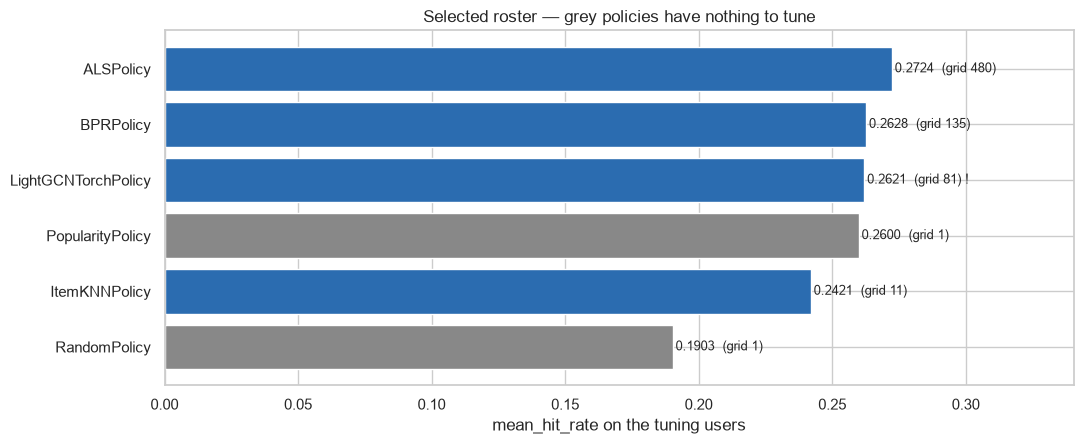

In [5]:
roster = report.panel_selected_roster(arts)
roster

## 5. Grid landscape

Each point is the mean objective over every grid point sharing that parameter value, so the axis
shows a marginal effect rather than a slice. Two readings:

- **A flat curve is a wasted axis.** `marginal_spread` ranks them, and it sizes the next revision
  better than intuition does — budget spent on a flat axis buys nothing but extra selection bias.
- **The dotted line is the selected value.** At the left or right edge of its axis, the search
  wanted to keep going.

The `max` trace sits above `mean` by construction; the gap between them is how much the *other*
axes matter at that value.

,policy,param,selected,marginal_spread,n_values
0,ALSPolicy,n_factors,4.0000,0.051086,6
1,ALSPolicy,alpha,20.0000,0.008172,4
2,ALSPolicy,iterations,50.0000,0.001759,4
3,ALSPolicy,regularization,0.0100,0.000991,5
4,BPRPolicy,regularization,0.1000,0.027050,3
5,BPRPolicy,iterations,1000.0000,0.013808,3
6,BPRPolicy,n_factors,8.0000,0.008633,5
7,BPRPolicy,learning_rate,0.0020,0.006743,3
8,ItemKNNPolicy,n_neighbors,150.0000,0.050345,11
9,LightGCNTorchPolicy,n_layers,4.0000,0.005977,3


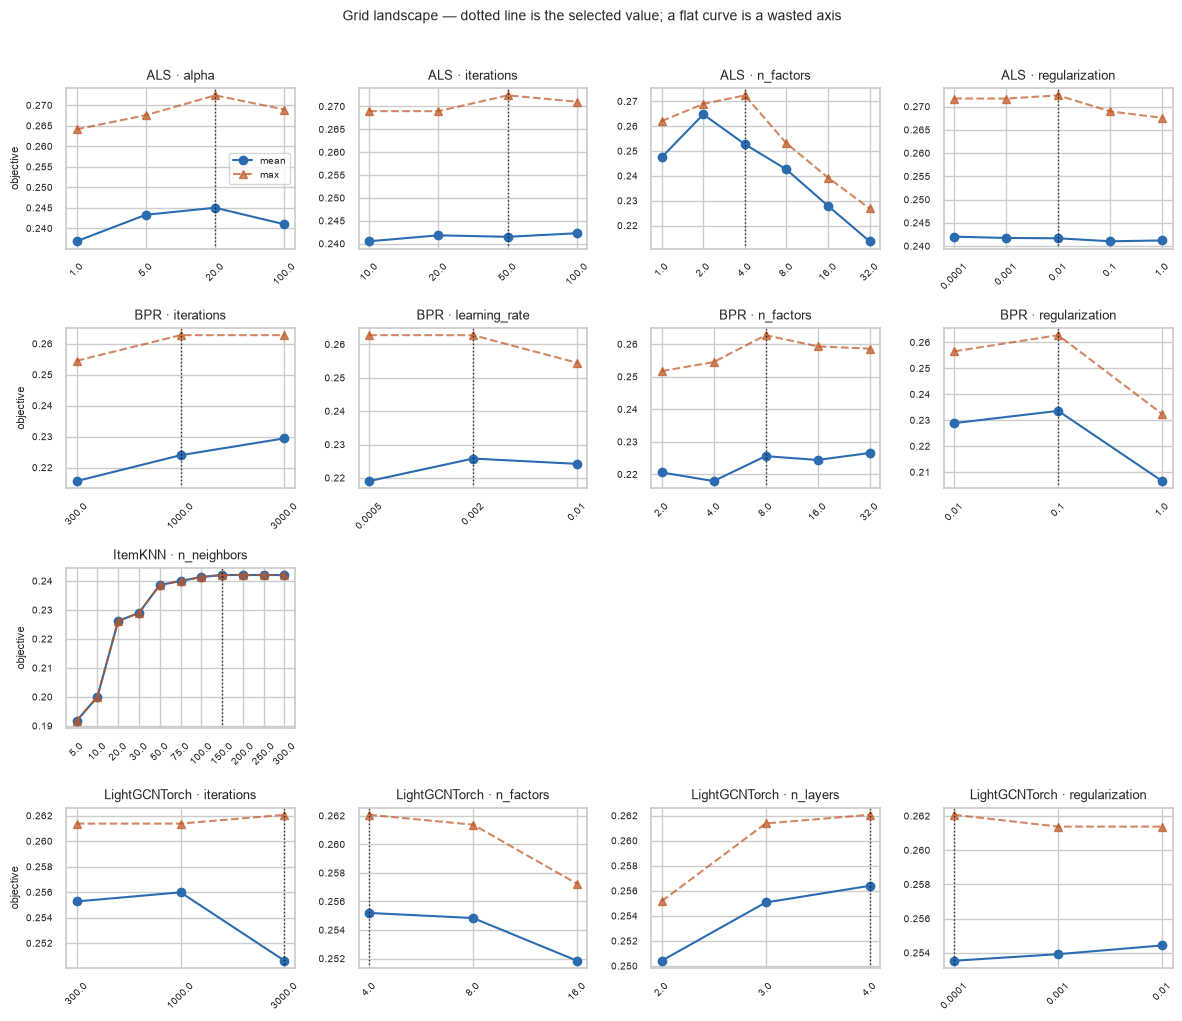

In [6]:
landscape = report.panel_grid_landscape(arts)
landscape

## 6. The winner's curse

**The centre of this notebook.** Keeping the best of G noisy estimates biases the winner's score
upward — not because the setting is bad, but because whichever setting drew the luckiest sample on
those users tends to win. Normally this costs nothing: you tune on validation and report on test.
Coat has no third partition, so the bias lands directly in the reference ordering τ is measured
against.

**How it is estimated.** Score *every* grid point on both diagnostic halves and take
`gap(s) = U_tuning(s) − U_holdout(s)`. Then

```
curse = gap(selected) − mean over all s of gap(s)
```

The grid mean never conditions on which point won, so it isolates the two halves' difficulty
difference; subtracting it leaves selection bias alone. Controlling with the policy's *own* grid
rather than another policy matters — settings of one recommender agree closely about which users are
easy, so the nuisance cancels almost exactly. An earlier version controlled against the baselines
and gave a CI nearly twice as wide.

**Self-check:** a one-point grid has `gap(selected) == grid mean`, so it reports exactly `0.0000`.
That is the correct answer — nothing was selected, so nothing could be inflated — and
`PopularityPolicy` / `RandomPolicy` reporting it every run verifies the estimator has not drifted.

That zero is also the problem: the two policies with nothing to tune are the two the collaborative
policies are being compared against.

Measured for a selection on 145 users; `curse_at_production` rescales to the 290-user selection by sqrt(145/290) = 0.707. That is an extrapolation.



,policy,grid_points,tuning_utility,holdout_utility,selected_gap,grid_mean_gap,curse,curse_lo,curse_hi,curse_at_production
0,ALSPolicy,480,0.275862,0.268966,0.006897,-0.007741,0.014598,-0.011779,0.040533,0.010322
1,BPRPolicy,135,0.267586,0.257931,0.009655,-0.001308,0.011695,-0.015961,0.040062,0.008270
2,ItemKNNPolicy,11,0.237241,0.240000,-0.002759,-0.012790,0.010016,-0.003135,0.023574,0.007083
3,LightGCNTorchPolicy,81,0.262069,0.259310,0.002759,-0.006403,0.009309,-0.002282,0.020896,0.006582
4,PopularityPolicy,1,0.263448,0.256552,0.006897,0.006897,0.000000,0.000000,0.000000,0.000000
5,RandomPolicy,1,0.184828,0.195862,-0.011034,-0.011034,0.000000,0.000000,0.000000,0.000000


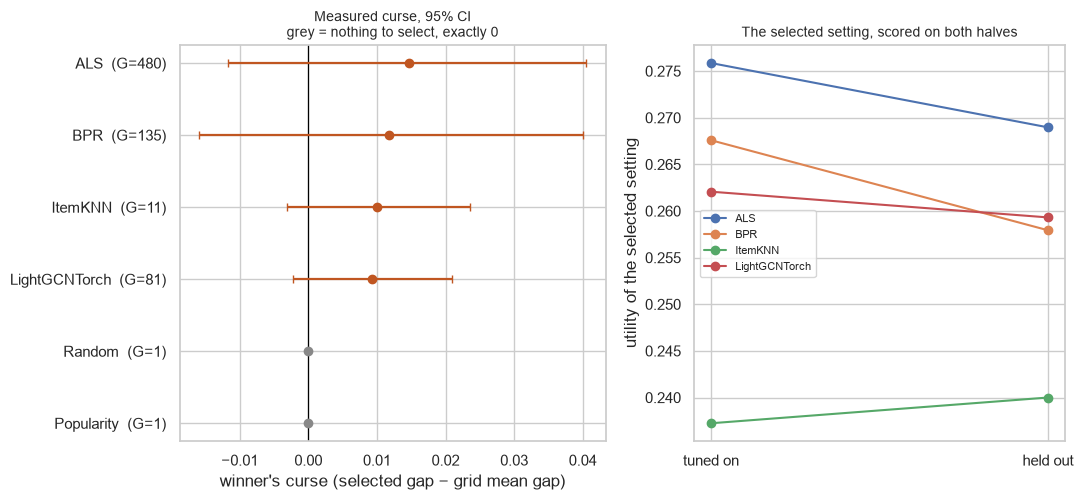

In [7]:
curse = report.panel_winners_curse(arts)
curse

### The worked example

One policy's full grid, both halves, sorted by gap. The selected row should sit at the top — that is
what "selected" means under this estimator. Watch the `U(holdout)` column: the winner is frequently
*not* the best setting on users it was not selected on.

In [8]:
report.gap_table(arts, "ItemKNNPolicy")

,n_neighbors,U(tuning),U(holdout),gap,selected
0,50.0,0.237241,0.240000,-0.002759,True
1,30.0,0.226207,0.231724,-0.005517,False
2,10.0,0.195862,0.204138,-0.008276,False
3,20.0,0.220690,0.231724,-0.011034,False
4,75.0,0.233103,0.246897,-0.013793,False
5,150.0,0.234483,0.249655,-0.015172,False
6,250.0,0.234483,0.249655,-0.015172,False
7,300.0,0.234483,0.249655,-0.015172,False
8,200.0,0.234483,0.249655,-0.015172,False
9,100.0,0.233103,0.249655,-0.016552,False


## 7. Does any lead survive its own bias?

The decisive panel. Utilities come from the run's `predictions.parquet` under a user-level
bootstrap, so they are the numbers the experiment actually reports, not the tuning objective.

A lead over Popularity has to clear two independent bars, and clearing one is not enough:

1. **Distinguishable** — the paired bootstrap CI on the margin excludes zero.
2. **Bigger than the bias that produced it** — the margin exceeds that policy's own curse, since
   Popularity has no hyperparameters and carries none.

`verdict` combines them. Note that a policy can exceed its curse and still fail, because the margin
CI includes zero at this sample size.

Using 20260818T184648Z_coat_policy_ranking_preference_rerank_seed0_popularity_scorer


,policy,utility,ci_lo,ci_hi,margin_over_Popularity,margin_lo,margin_hi,curse,verdict
0,ALSPolicy,0.272414,0.244828,0.301379,0.012414,-0.009655,0.033103,0.010322,not distinguishable
1,BPRPolicy,0.262759,0.234466,0.292414,0.002759,-0.020000,0.024138,0.008270,not distinguishable
2,LightGCNTorchPolicy,0.262069,0.233793,0.291034,0.002069,-0.021379,0.024138,0.006582,not distinguishable
3,PopularityPolicy,0.260000,0.230345,0.291034,0.000000,0.000000,0.000000,0.000000,-
4,ItemKNNPolicy,0.242069,0.215172,0.271034,-0.017931,-0.038621,0.002759,0.007083,behind
5,RandomPolicy,0.190345,0.164138,0.218621,-0.069655,-0.091034,-0.047586,0.000000,behind


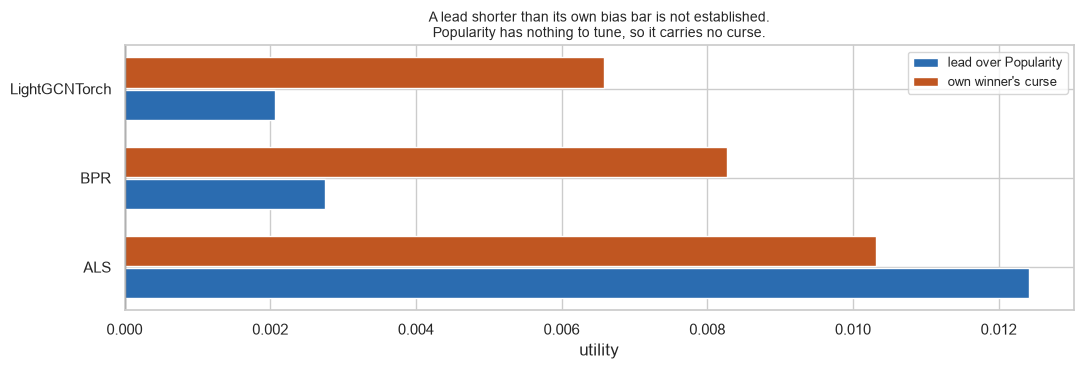

In [9]:
RUN_DIRS = sorted(RUNS_DIR.glob("*popularity_scorer"))
LATEST_RUN = RUN_DIRS[-1]
print(f"Using {LATEST_RUN.name}")

margins = report.panel_curse_vs_margins(arts, LATEST_RUN)
margins

## 8. Did tuning change the roster?

Compares the untuned hand-written roster against the tuned one on the same evaluation frame.

`resolvable_pairs` is the Gate C question: of the C(6,2) = 15 policy pairs, how many have
non-overlapping 95% CIs. It governs how the headline τ may be read — a rank correlation computed
over pairs that are mostly unresolvable is mostly measuring noise, whatever its value.

`spread_excl_random` is the one to watch. Total spread can grow while the five non-Random policies
stay just as compressed, and it is that compression, not the distance to Random, that determines
whether the ordering carries information.

           spread  spread_excl_random  mean_ci_half_width  resolvable_pairs  total_pairs               top
roster                                                                                                    
untuned  0.069655            0.033793            0.027471                 3           15  PopularityPolicy
tuned    0.082069            0.030345            0.028565                 4           15         ALSPolicy



roster,tuned,untuned
policy,,
ALSPolicy,0.272414,0.253103
BPRPolicy,0.262759,0.240000
ItemKNNPolicy,0.242069,0.226207
LightGCNTorchPolicy,0.262069,0.256552
PopularityPolicy,0.260000,0.260000
RandomPolicy,0.190345,0.190345


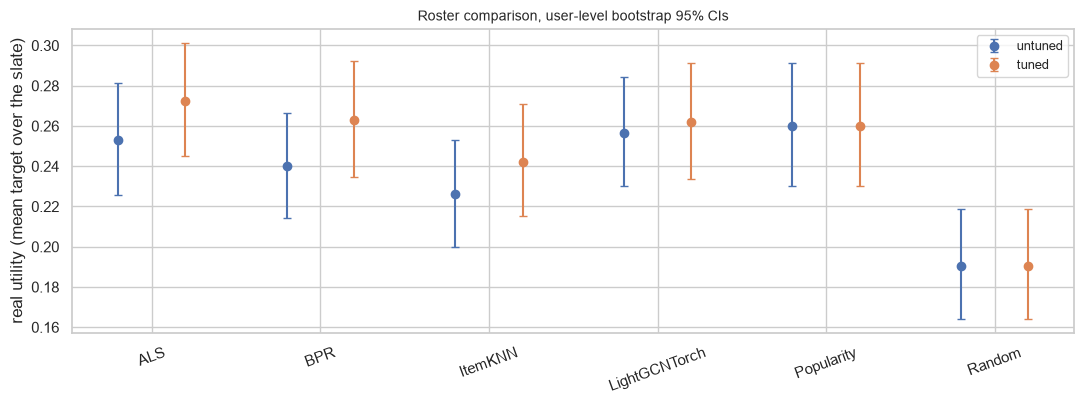

In [10]:
comparison = report.panel_roster_comparison({
    "untuned": RUN_DIRS[0],
    "tuned": LATEST_RUN,
})
comparison.pivot(index="policy", columns="roster", values="utility")

## 9. Cost

Where the budget went, and what a further box revision would cost. Wall time covers fit *and*
ranking; for ItemKNN ranking is ~90% of it, so a fit-only timer would under-size the next sweep by
two orders of magnitude.

`max_fallback_users` is a correctness signal, not a cost one: it counts users for whom the policy
returned the seeded shuffle because it had no signal for them. `RandomPolicy` is at 100% by
definition. A tuned policy with a high count was partly Random at that grid point, and its objective
is not comparable to its neighbours'.

In [11]:
cost = report.panel_cost(arts)
cost

diagnostic: 709 points, 8.5 min of fit+rank
production: 709 points, 7.1 min of fit+rank



,arm,policy,points,total_seconds,seconds_per_point,max_fallback_users
0,diagnostic,LightGCNTorchPolicy,81,422.000281,5.209880,3
1,diagnostic,BPRPolicy,135,35.813649,0.265286,3
2,diagnostic,ALSPolicy,480,34.895254,0.072698,3
3,diagnostic,ItemKNNPolicy,11,19.832636,1.802967,47
4,diagnostic,PopularityPolicy,1,0.058398,0.058398,0
5,diagnostic,RandomPolicy,1,0.049832,0.049832,145
6,production,LightGCNTorchPolicy,81,340.898116,4.208619,3
7,production,ALSPolicy,480,34.179726,0.071208,3
8,production,BPRPolicy,135,32.263614,0.238990,3
9,production,ItemKNNPolicy,11,18.182233,1.652930,104


In [12]:
if SAVE_FIGS:
    written = report.save_open_figures(FIG_DIR, prefix=f"{DATASET}_rerank_")
    print(f"Wrote {len(written)} figure(s) to {FIG_DIR}")

## Findings

_Fill in after running. The panels above are the evidence; this cell is the read-out for the paper._

Carry forward from the current run:

- **Tuning worked, and did not help.** Utilities rose and ALS overtook Popularity, but the five
  non-Random policies got no easier to tell apart: `spread_excl_random` went 0.0338 → 0.0303 against
  a mean CI half-width of 0.0286, and `resolvable_pairs` moved only 3 → 4 of 15. Every separation is
  still against Random. The roster resolves into "Random" and "everything else".
- **No lead over Popularity is established** (§7). Every contender's `verdict` is
  `not distinguishable`: the paired margin CIs include zero, and the point margins are the same size
  as the selection bias that produced them.
- **The collaborative policies shrink toward popularity.** ItemKNN selects 150 of 300 possible
  neighbours and ALS selects `n_factors=4` — both close to the degenerate end of their axis. On 290
  users × 300 items with 6.3 positives per user, that looks like a property of the dataset rather
  than of the hyperparameters. LightGCN is the exception worth stating precisely: it wants a *small
  model trained long* (`n_factors` at the floor, `n_layers` and `iterations` at the ceiling, weight
  decay at the floor), which is not the same direction, and it is the one policy still on a
  boundary — its optimum is flat, so widening would chase noise.
- **Un-modelled selection:** the search boxes were revised four times against these same labels.
  §6 controls for choosing a point within a grid, not for choosing the grid.